# Fast Food Marketing Campaign — A/B/C Test

## 1. Goal

A fast-food chain plans to add a new item to its menu but is undecided between
**three possible marketing campaigns** for promoting it. To find out which
promotion has the greatest effect on sales, the new item was introduced at
locations in several randomly selected markets. Each location ran **one**
promotion, and weekly sales of the new item were recorded for the **first four
weeks**.

**Goal of the test:** identify the promotion that sells the most of the new
item, so the chain can roll that promotion out to all its stores.

**Data** (one row per location per week):

| Column | Meaning |
|---|---|
| `MarketID` | market (city/region) the store is in — 10 markets |
| `MarketSize` | size of the market: Small / Medium / Large |
| `LocationID` | unique store id |
| `AgeOfStore` | store age in years |
| `Promotion` | promotion the store ran: 1, 2 or 3 |
| `week` | week of the test: 1–4 |
| `SalesInThousands` | sales of the new item that week, in thousands of $ |

## 2. Target metric

**Average weekly sales of the new item per location** (thousands of $),
averaged over the four test weeks.

- It measures the goal directly: the chain wants the promotion that sells the
  most of the new item.
- The **location** is the unit that was randomised — every store ran one
  promotion for all four weeks. The four weekly numbers from the same store
  are not independent (same customers, same neighbourhood), so treating the
  548 rows as 548 independent samples would make us look more certain than we
  are. Averaging to one number per store gives **137 independent
  observations**, one per randomised unit.
- The week-by-week numbers are still used, to check that the difference
  between promotions is stable over time rather than a one-week spike.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from matplotlib.ticker import FuncFormatter
from scipy import stats

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

PROMOS = [1, 2, 3]
COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
NEUTRAL = "#8a8985"
ALPHA = 0.05
N_COMPARISONS = 3
CI_LEVEL = 1 - ALPHA / N_COMPARISONS  # Bonferroni-adjusted interval
PAIRS = [(1, 2), (1, 3), (3, 2)]
DOLLARS = FuncFormatter(lambda x, _: f"${x:,.0f}k")


def signed_dollars(x, _):
    """Axis label for a difference, e.g. +$5k / −$5k."""
    sign = "+" if x > 0 else "−" if x < 0 else ""
    return f"{sign}${abs(x):,.0f}k"

## 3. Calculations

### 3.1 Load and check the data

In [2]:
sales = pd.read_csv("WA_Marketing-Campaign.csv")
print(sales.shape)
sales.head()

(548, 7)


,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.7300
1,1,Medium,1,4,3,2,35.6700
2,1,Medium,1,4,3,3,29.0300
3,1,Medium,1,4,3,4,39.2500
4,1,Medium,2,5,2,1,27.8100


In [3]:
print("Missing values:", sales.isna().sum().sum())
print("Duplicate (location, week) rows:",
      sales.duplicated(["LocationID", "week"]).sum())

per_location = sales.groupby("LocationID").agg(
    promotions=("Promotion", "nunique"),
    weeks=("week", "nunique"),
)
print("Locations with more than one promotion:",
      (per_location["promotions"] > 1).sum())
print("Locations without all 4 weeks:", (per_location["weeks"] != 4).sum())

Missing values: 0
Duplicate (location, week) rows: 0
Locations with more than one promotion: 0
Locations without all 4 weeks: 0


The data is clean: no missing values, no duplicates, every store ran exactly
one promotion and has all four weeks. Next, aggregate to **one row per
location** — the target metric.

In [4]:
locations = sales.groupby(
    ["LocationID", "MarketID", "MarketSize", "AgeOfStore", "Promotion"],
    as_index=False,
)["SalesInThousands"].mean()
locations = locations.rename(columns={"SalesInThousands": "avg_weekly_sales"})
print(locations.shape)
locations.head()

(137, 6)


,LocationID,MarketID,MarketSize,AgeOfStore,Promotion,avg_weekly_sales
0,1,1,Medium,4,3,34.4200
1,2,1,Medium,5,2,29.5450
2,3,1,Medium,12,1,40.6800
3,4,1,Medium,1,2,33.7075
4,5,1,Medium,10,2,29.0025


### 3.2 Sample size, variant proportions and sample ratio mismatch (SRM)

With three promotions assigned at random we expect roughly **one third** of
locations in each group. A chi-square goodness-of-fit test checks whether the
observed counts are consistent with an equal split. A significant result would
suggest a bug in how stores were assigned.

In [5]:
counts = locations["Promotion"].value_counts().reindex(PROMOS)
srm_chi2, srm_p = stats.chisquare(counts)

pd.DataFrame({
    "locations": counts,
    "share": counts / counts.sum(),
    "weekly_rows": sales["Promotion"].value_counts().reindex(PROMOS),
}).rename_axis("Promotion")

,locations,share,weekly_rows
Promotion,,,
1,43,0.3139,172
2,47,0.3431,188
3,47,0.3431,188


In [6]:
print(f"Total locations: {counts.sum()}")
print(f"SRM chi-square = {srm_chi2:.3f}, p = {srm_p:.3f}")

Total locations: 137
SRM chi-square = 0.234, p = 0.890


The split is 43 / 47 / 47 locations (31% / 34% / 34%). The SRM test is **not
significant (p ≈ 0.89)**: a gap this size is what random assignment
typically produces, so there is no sign of a randomisation bug.

### 3.3 Are the groups comparable?

Randomisation should also balance store characteristics. Market size and
store age both plausibly affect sales, so we check them.

In [7]:
size_mix = pd.crosstab(locations["Promotion"], locations["MarketSize"])
_, size_p, _, _ = stats.chi2_contingency(size_mix)
age_p = stats.kruskal(
    *[locations.loc[locations["Promotion"] == p, "AgeOfStore"]
      for p in PROMOS]
).pvalue

print(size_mix, end="\n\n")
print(f"Market size vs promotion: chi-square p = {size_p:.3f}")
print(f"Store age vs promotion:   Kruskal-Wallis p = {age_p:.3f}")

MarketSize  Large  Medium  Small
Promotion                       
1              14      24      5
2              16      27      4
3              12      29      6

Market size vs promotion: chi-square p = 0.880
Store age vs promotion:   Kruskal-Wallis p = 0.563


Market size and store age are balanced across promotions (both p > 0.05).
However, the 10 **individual markets** differ a lot in sales level, and
the promotions are not spread evenly across them (e.g. market 2 has five
Promotion 3 stores but only one Promotion 1 store). The chart below shows how
large the market effect is.

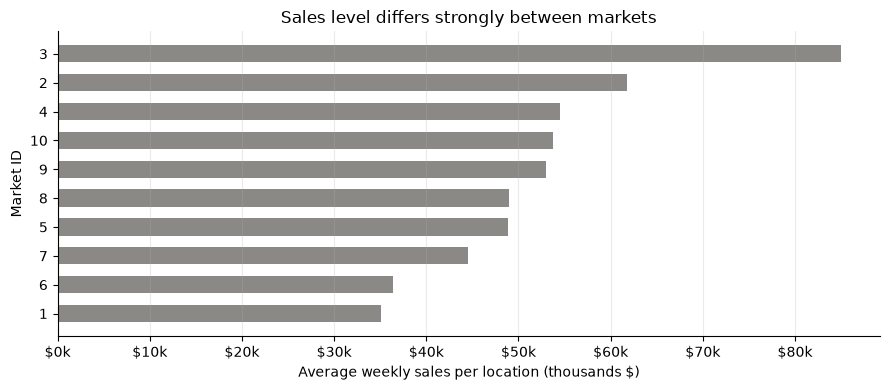

In [8]:
market_mean = (locations.groupby("MarketID")["avg_weekly_sales"]
               .mean().sort_values())

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(market_mean.index.astype(str), market_mean.values,
        color=NEUTRAL, height=0.6)
ax.xaxis.set_major_formatter(DOLLARS)
ax.set_xlabel("Average weekly sales per location (thousands $)")
ax.set_ylabel("Market ID")
ax.set_title("Sales level differs strongly between markets")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Average sales per store range from about \$35k to \$85k a week depending on
the market. This market-to-market variation is much larger than the
differences between promotions, so it adds a lot of noise to a simple
comparison. Section 3.6 repeats the analysis **controlling for market** as a
robustness check.

### 3.4 Target metric by promotion

In [9]:
summary = locations.groupby("Promotion")["avg_weekly_sales"].agg(
    ["count", "mean", "std", "median"]
)
summary["sem"] = summary["std"] / np.sqrt(summary["count"])
t_crit = stats.t.ppf(1 - ALPHA / 2, summary["count"] - 1)
summary["ci_low"] = summary["mean"] - t_crit * summary["sem"]
summary["ci_high"] = summary["mean"] + t_crit * summary["sem"]
summary

,count,mean,std,median,sem,ci_low,ci_high
Promotion,,,,,,,
1,43,58.0990,16.0282,56.0750,2.4443,53.1663,63.0318
2,47,47.3294,14.4971,46.6550,2.1146,43.0729,51.5859
3,47,55.3645,16.3839,49.8525,2.3898,50.5540,60.1750


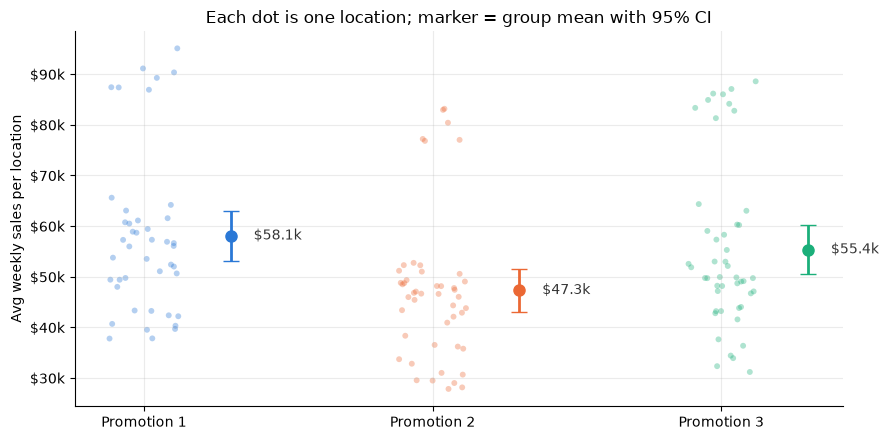

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
jitter = np.random.default_rng(0).uniform(-0.12, 0.12, len(locations))
ax.scatter(locations["Promotion"] + jitter, locations["avg_weekly_sales"],
           s=18, alpha=0.35,
           color=locations["Promotion"].map(COLORS), linewidths=0)
for p in PROMOS:
    row = summary.loc[p]
    ax.errorbar(p + 0.3, row["mean"],
                yerr=[[row["mean"] - row["ci_low"]],
                      [row["ci_high"] - row["mean"]]],
                fmt="o", ms=8, color=COLORS[p], capsize=6, elinewidth=2)
    ax.text(p + 0.38, row["mean"], f"${row['mean']:.1f}k",
            va="center", color="#333")
ax.set_xticks(PROMOS, [f"Promotion {p}" for p in PROMOS])
ax.yaxis.set_major_formatter(DOLLARS)
ax.set_ylabel("Avg weekly sales per location")
ax.set_title("Each dot is one location; marker = group mean with 95% CI")
plt.tight_layout()
plt.show()

Promotion 1 has the highest mean (\$58.1k), Promotion 3 is close behind
(\$55.4k) and Promotion 2 is clearly lowest (\$47.3k). The distributions
overlap heavily, though, so we need formal tests.

### 3.5 Statistical tests

The target metric is a **continuous amount of money**, not a count or a
yes/no outcome, so the chi-square and binomial tests do not apply — we compare
**means**.

1. **One-way ANOVA** — is there *any* difference between the three
   promotions? Assumptions: independent observations (one per randomised
   location ✔), roughly normal group means (≈45 locations per group, so the
   central limit theorem applies ✔), similar variances (checked with Levene's
   test below).
2. **Welch's t-test** for each pair of promotions — *which* promotions differ,
   and by how much? Welch's version does not assume equal variances, so it is
   the safer default. Because we run three comparisons, the chance of at least
   one false positive grows, so we apply the **Bonferroni correction**: each
   p-value is multiplied by 3, and the confidence intervals are widened to
   1 − 0.05/3 ≈ **98.3%** so they agree with the adjusted p-values.

Hypotheses for each pair: **H₀** the two promotions have equal mean sales;
**H₁** they differ (two-sided), α = 0.05.

In [11]:
groups = {p: locations.loc[locations["Promotion"] == p, "avg_weekly_sales"]
          for p in PROMOS}

anova = stats.f_oneway(*groups.values())
levene = stats.levene(*groups.values())
print(f"ANOVA:  F = {anova.statistic:.2f}, p = {anova.pvalue:.4f}")
print(f"Levene: W = {levene.statistic:.2f}, p = {levene.pvalue:.4f}")

ANOVA:  F = 5.85, p = 0.0037
Levene: W = 0.47, p = 0.6272


The ANOVA is significant (p ≈ 0.004): at least one promotion differs.
Levene's test (p ≈ 0.63) shows no evidence of unequal variances, so the ANOVA
assumptions hold. Now the pairwise comparisons:

In [12]:
def welch_comparison(a, b):
    """Welch t-test of mean(a) - mean(b) with Bonferroni adjustment."""
    result = stats.ttest_ind(a, b, equal_var=False)
    ci = result.confidence_interval(confidence_level=CI_LEVEL)
    return {
        "effect": a.mean() - b.mean(),
        "ci_low": ci.low,
        "ci_high": ci.high,
        "p_value": result.pvalue,
        "p_adjusted": min(result.pvalue * N_COMPARISONS, 1.0),
    }


pairwise = pd.DataFrame(
    [welch_comparison(groups[a], groups[b]) for a, b in PAIRS],
    index=[f"Promo {a} − Promo {b}" for a, b in PAIRS],
)
pairwise["significant"] = pairwise["p_adjusted"] < ALPHA
pairwise

,effect,ci_low,ci_high,p_value,p_adjusted,significant
Promo 1 − Promo 2,10.7696,2.8759,18.6633,0.0013,0.0038,True
Promo 1 − Promo 3,2.7345,-5.6093,11.0784,0.4259,1.0000,False
Promo 3 − Promo 2,8.0351,0.2514,15.8187,0.0136,0.0407,True


**Estimated treatment effects** (thousands of $ per location per week,
98.3% Bonferroni CI):

- **Promotion 1 vs 2:** +\$10.8k (CI +\$2.9k to +\$18.7k), adjusted
  p ≈ 0.004 → **significant**.
- **Promotion 3 vs 2:** +\$8.0k (CI +\$0.3k to +\$15.8k), adjusted
  p ≈ 0.04 → **significant**.
- **Promotion 1 vs 3:** +\$2.7k (CI −\$5.6k to +\$11.1k), adjusted
  p ≈ 1 → **not significant**: the interval includes zero, so this
  comparison alone cannot separate Promotions 1 and 3.

**Where does the uncertainty come from?** We only observed 43–47 stores per
promotion, and stores differ widely from one another (standard deviation
≈ \$16k), much of it because they sit in different markets. A different
random draw of stores would give somewhat different averages. The confidence
interval shows the range of true effects that are consistent with the data
we have.

### 3.6 Robustness check: controlling for market

Each market has its own baseline sales level, and the promotions are not
evenly spread across markets. A linear regression of the target metric on
promotion **plus a separate intercept per market** (market fixed effects)
compares promotions *within the same market*, which removes that noise.
Heteroscedasticity-robust (HC3) standard errors are used, and the same
Bonferroni-adjusted interval level.

In [13]:
model = smf.ols(
    "avg_weekly_sales ~ C(Promotion) + C(MarketID)", data=locations
).fit(cov_type="HC3")

PROMO_TERM = "C(Promotion)[T.{}]"


def contrast_string(a, b):
    """Regression contrast for Promotion a minus Promotion b (1 = baseline)."""
    terms = {p: PROMO_TERM.format(p) if p != 1 else "0" for p in PROMOS}
    return f"{terms[a]} - {terms[b]} = 0".replace("0 - ", "-")


def market_adjusted_comparison(a, b):
    """Market-adjusted effect of Promotion a over b, Bonferroni-adjusted."""
    test = model.t_test(contrast_string(a, b))
    low, high = test.conf_int(alpha=1 - CI_LEVEL)[0]
    p_value = float(test.pvalue)
    return {
        "effect": float(test.effect[0]),
        "ci_low": low,
        "ci_high": high,
        "p_value": p_value,
        "p_adjusted": min(p_value * N_COMPARISONS, 1.0),
    }


adjusted = pd.DataFrame(
    [market_adjusted_comparison(a, b) for a, b in PAIRS],
    index=pairwise.index,
)
adjusted["significant"] = adjusted["p_adjusted"] < ALPHA
adjusted

,effect,ci_low,ci_high,p_value,p_adjusted,significant
Promo 1 − Promo 2,9.7180,8.3970,11.0390,0.0000,0.0000,True
Promo 1 − Promo 3,4.9249,3.5245,6.3253,0.0000,0.0000,True
Promo 3 − Promo 2,4.7931,3.2596,6.3267,0.0000,0.0000,True


Once each store is compared only with stores in the same market, the
estimates become **much more precise** and all three differences are
significant. Promotion 1 beats Promotion 3 by about **\$4.9k** per store per
week, and Promotion 2 is still the weakest. The ordering is the same as in the
simple comparison (1 > 3 > 2), so the two methods agree.

## 4. Decision

### 4.1 Treatment effects with confidence intervals

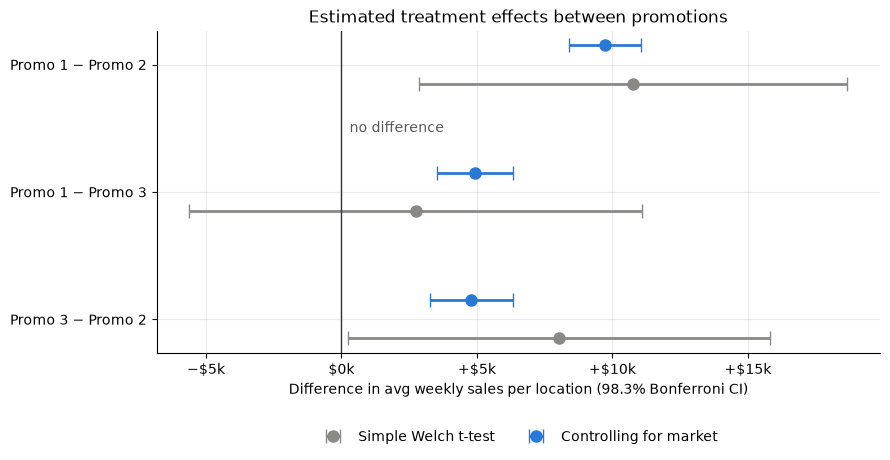

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(PAIRS))
offset = 0.15
for frame, shift, color, label in [
    (pairwise, offset, NEUTRAL, "Simple Welch t-test"),
    (adjusted, -offset, "#2a78d6", "Controlling for market"),
]:
    ax.errorbar(frame["effect"], y + shift,
                xerr=[frame["effect"] - frame["ci_low"],
                      frame["ci_high"] - frame["effect"]],
                fmt="o", ms=8, color=color, capsize=5, elinewidth=2,
                label=label)
ax.axvline(0, color="#333", linewidth=1)
ax.text(0.3, 0.5, "no difference", color="#555", va="center")
ax.set_yticks(y, pairwise.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(signed_dollars))
ax.set_xlabel("Difference in avg weekly sales per location "
              "(98.3% Bonferroni CI)")
ax.set_title("Estimated treatment effects between promotions")
ax.legend(frameon=False, loc="upper center", ncols=2,
          bbox_to_anchor=(0.5, -0.2))
plt.tight_layout()
plt.show()

### 4.2 Is the effect stable across the four weeks?

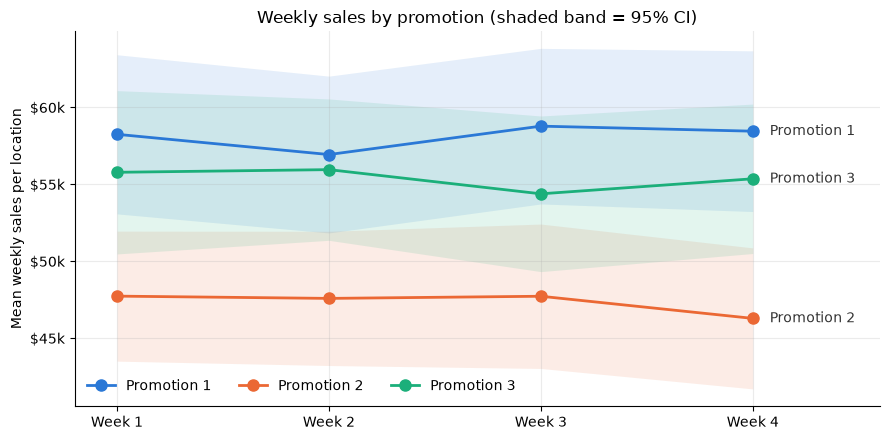

In [15]:
weekly = sales.groupby(["week", "Promotion"])["SalesInThousands"].agg(
    ["mean", "sem", "count"]
).reset_index()
weekly_t = stats.t.ppf(1 - ALPHA / 2, weekly["count"] - 1)
weekly["ci_low"] = weekly["mean"] - weekly_t * weekly["sem"]
weekly["ci_high"] = weekly["mean"] + weekly_t * weekly["sem"]

fig, ax = plt.subplots(figsize=(9, 4.5))
for p in PROMOS:
    w = weekly[weekly["Promotion"] == p]
    ax.fill_between(w["week"], w["ci_low"], w["ci_high"],
                    color=COLORS[p], alpha=0.12, linewidth=0)
    ax.plot(w["week"], w["mean"], marker="o", ms=8, linewidth=2,
            color=COLORS[p], label=f"Promotion {p}")
    ax.text(4.08, w["mean"].iloc[-1], f"Promotion {p}",
            va="center", color="#333")
ax.set_xticks([1, 2, 3, 4], [f"Week {w}" for w in range(1, 5)])
ax.set_xlim(0.8, 4.6)
ax.yaxis.set_major_formatter(DOLLARS)
ax.set_ylabel("Mean weekly sales per location")
ax.set_title("Weekly sales by promotion (shaded band = 95% CI)")
ax.legend(frameon=False, loc="lower left", ncols=3)
plt.tight_layout()
plt.show()

The ranking **Promotion 1 > Promotion 3 > Promotion 2 holds in every one of
the four weeks**, and none of the lines trends up or down. The difference is
not a novelty spike that fades after the first week.

#### How the target metric builds up week by week
The target metric is each store's **average weekly sales over the test period**. The chart
below recalculates it as each week of data is added: first from week 1 only, then weeks
1–2, and so on. It shows what we would have concluded had we stopped the test early.

In [ ]:
cumulative = []
for last_week in range(1, 5):
    so_far = (sales[sales["week"] <= last_week]
              .groupby(["LocationID", "Promotion"], as_index=False)
              ["SalesInThousands"].mean())
    for p in PROMOS:
        store_avgs = so_far.loc[so_far["Promotion"] == p, "SalesInThousands"]
        sem = stats.sem(store_avgs)
        t_crit = stats.t.ppf(1 - ALPHA / 2, len(store_avgs) - 1)
        cumulative.append({
            "weeks_included": last_week,
            "Promotion": p,
            "mean": store_avgs.mean(),
            "ci_low": store_avgs.mean() - t_crit * sem,
            "ci_high": store_avgs.mean() + t_crit * sem,
        })
cumulative = pd.DataFrame(cumulative)

fig, ax = plt.subplots(figsize=(9, 4.8))
for p in PROMOS:
    c = cumulative[cumulative["Promotion"] == p]
    ax.fill_between(c["weeks_included"], c["ci_low"], c["ci_high"],
                    color=COLORS[p], alpha=0.12, linewidth=0)
    ax.plot(c["weeks_included"], c["mean"], marker="o", ms=8, linewidth=2,
            color=COLORS[p], markeredgecolor="white", markeredgewidth=1.5)
    last = c.iloc[-1]
    ax.text(4.1, last["mean"], f"Promotion {p}  ${last['mean']:.1f}k",
            va="center", color="#333")
ax.set_xticks([1, 2, 3, 4],
              ["Week 1", "Weeks 1–2", "Weeks 1–3", "Weeks 1–4"])
ax.set_xlim(0.8, 4.9)
ax.yaxis.set_major_locator(plt.MultipleLocator(5))
ax.yaxis.set_major_formatter(DOLLARS)
ax.set_xlabel("Data included so far")
ax.set_ylabel("Avg weekly sales per location")
ax.set_title("Target metric as each week is added (shaded band = 95% CI)")
plt.tight_layout()
plt.show()

cumulative.pivot(index="weeks_included", columns="Promotion", values="mean")

The target metric barely moves as weeks are added. After week 1 alone the averages were
\$58.2k / \$47.7k / \$55.8k; after all four weeks they are \$58.1k / \$47.3k / \$55.4k. The
ranking **1 > 3 > 2 was already visible after the first week** and never changed.

The confidence bands also hardly narrow as weeks are added. The uncertainty comes mainly
from the **differences between stores**, not from week-to-week noise. Running the test for
more weeks would add little precision; testing **more stores** would add a lot.

#### Treatment effect week by week
The chart below runs the Section 3.5 and 3.6 comparisons **separately for each week**:
the same Welch t-test and market-adjusted regression, with the same 98.3% Bonferroni
intervals. The dashed line is the 4-week market-adjusted estimate from Section 3.6.

In [ ]:
def weekly_effects(week, week_data):
    """Effect of each promotion pair in one week: simple and market-adjusted."""
    week_groups = {p: week_data.loc[week_data["Promotion"] == p,
                                    "SalesInThousands"] for p in PROMOS}
    week_model = smf.ols("SalesInThousands ~ C(Promotion) + C(MarketID)",
                         data=week_data).fit(cov_type="HC3")
    rows = []
    for a, b in PAIRS:
        simple = stats.ttest_ind(week_groups[a], week_groups[b],
                                 equal_var=False)
        low, high = simple.confidence_interval(confidence_level=CI_LEVEL)
        rows.append({"week": week, "pair": f"Promo {a} − Promo {b}",
                     "method": "Simple Welch t-test",
                     "effect": week_groups[a].mean() - week_groups[b].mean(),
                     "ci_low": low, "ci_high": high})
        test = week_model.t_test(contrast_string(a, b))
        low, high = test.conf_int(alpha=1 - CI_LEVEL)[0]
        rows.append({"week": week, "pair": f"Promo {a} − Promo {b}",
                     "method": "Controlling for market",
                     "effect": float(test.effect[0]),
                     "ci_low": low, "ci_high": high})
    return rows


effects = pd.DataFrame([row for week, week_data in sales.groupby("week")
                        for row in weekly_effects(week, week_data)])

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
for ax, pair in zip(axes, effects["pair"].unique()):
    for method, shift, color in [("Simple Welch t-test", -0.1, NEUTRAL),
                                 ("Controlling for market", 0.1, "#2a78d6")]:
        e = effects[(effects["pair"] == pair) & (effects["method"] == method)]
        ax.errorbar(e["week"] + shift, e["effect"],
                    yerr=[e["effect"] - e["ci_low"], e["ci_high"] - e["effect"]],
                    fmt="o", ms=7, color=color, capsize=4, elinewidth=2,
                    label=method)
    ax.axhline(0, color="#333", linewidth=1)
    ax.axhline(adjusted.loc[pair, "effect"], color="#2a78d6", linewidth=1,
               linestyle="--", alpha=0.7)
    ax.set_title(pair)
    ax.set_xticks([1, 2, 3, 4], [f"Wk {w}" for w in range(1, 5)])
    ax.set_xlim(0.5, 4.5)
axes[0].yaxis.set_major_formatter(FuncFormatter(signed_dollars))
axes[0].set_ylabel("Difference in weekly sales per location")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="lower center", ncols=2)
fig.suptitle("Treatment effect week by week (98.3% Bonferroni CI; "
             "dashed = 4-week market-adjusted estimate)")
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

Promotion 1 is ahead of Promotion 2 by about \$8–11k **in every single week**, and the
interval never comes near zero. Promotion 1 also beats Promotion 3 and Promotion 3 beats
Promotion 2 every week once market is controlled for: the blue intervals stay above zero
throughout. None of the effects grows or shrinks steadily over time; week-to-week changes
stay well inside the intervals. The simple (grey) intervals are much wider, and for
Promotion 1 vs 3 they cross zero every week, as in Section 3.5: market differences add a
lot of noise.

Each week here uses only a quarter of the data, so a single week's interval is wider than
the 4-week result. The decision is based on the full 4-week analysis. This chart shows that
the result **holds week after week** and is not driven by one unusual week.

### 4.3 Recommendation

| | Promo 1 vs 2 | Promo 3 vs 2 | Promo 1 vs 3 |
|---|---|---|---|
| Simple Welch t-test | **+\$10.8k**, significant | **+\$8.0k**, significant | +\$2.7k, not significant |
| Controlling for market | **+\$9.7k**, significant | **+\$4.8k**, significant | **+\$4.9k**, significant |

**Recommendation: roll out Promotion 1.**

- **Promotion 2 should be dropped.** Both methods agree it sells roughly
  \$8–11k less of the new item per store per week than Promotion 1, roughly
  18–20% lower.
- **Promotion 1 vs Promotion 3** is the closer call. The simple comparison
  cannot tell them apart, because store-to-store variation between markets
  hides the difference. Once each store is compared with stores in the same
  market, Promotion 1 comes out ahead by about \$5k per store per week, and
  it led in every week. Promotion 1 is therefore the best choice on the
  evidence we have.
- If Promotion 3 were much **cheaper** to run, the decision should weigh that
  cost against the ≈\$5k/week sales gap. Cost data is not in this dataset.

**Limitations**

- Only four weeks of data: long-term effects (e.g. promotion fatigue) are
  unknown.
- Only sales of the new item are measured. A promotion could pull sales
  away from other menu items (cannibalisation), which this test cannot see.
- The market-adjusted result relies on a regression model. It agrees with
  the simple test on direction, which makes it more credible, but it is
  still a modelling choice.

### 4.4 Dashboard

The key results of this test (and of the Cookie Cats test) are summarised in an
interactive dashboard: **[A/B Test Results dashboard](https://claude.ai/artifact/SaBVAPZSgGkDjRTq28K2DB)**.